# Diagnóstico Automático de Eletrocardiogramas com Transformers
## Notebook 01 - Análise Exploratória e Preparação dos Dados (MIT-BIH Arrhythmia Database)

**Projeto da Disciplina em Grupo - Inteligência Artificial (7º CC, Turma 7N) - Parte 3 (N2)**
Universidade Presbiteriana Mackenzie - Faculdade de Computação e Informática
Professor: Prof. Dr. Ivan Carlos Alcântara de Oliveira

Integrantes:
- Enzo Ponte Gamberi - RA 10389931 - 10389931@mackenzista.com.br
- João Guilherme Messias de Oliveira Santos - RA 10426110 - 10426110@mackenzista.com.br
- Luís Henrique Ribeiro Fernandes - RA 10420079 - 10420079@mackenzista.com.br

---

**Síntese do conteúdo do arquivo:** baixa os 48 registros do MIT-BIH Arrhythmia Database
(PhysioNet), descreve os registros e o perfil dos pacientes, analisa o sinal e a distribuição das
classes de batimento (por registro e na divisão inter-paciente DS1/DS2), examina os atributos de
ritmo (intervalos RR) e gera o conjunto processado usado no notebook 02 (treino e avaliação do
Transformer). As funções de pré-processamento estão em `src/ecg_utils.py`.

**Histórico de alterações:**
- 2026-09-25, Grupo (Enzo, João, Luís): criação do notebook na Parte 2 (N1), com 20 registros,
  análise exploratória, pré-processamento e split aleatório estratificado.
- 2026-11-19, João Guilherme: ampliação para os 48 registros; exclusão dos 4 registros com
  marcapasso; perfil dos pacientes; divisão inter-paciente DS1/DS2; análise dos intervalos RR;
  janela de 256 amostras; canal de morfologia relativa; pré-processamento movido para
  `src/ecg_utils.py`.

In [1]:
# Bibliotecas e caminhos
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..') / 'src'))
import ecg_utils as eu

RAW_DIR = Path('../dataset/raw/mitdb')
PROC_DIR = Path('../dataset/processed')
PROC_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

# Baixa do PhysioNet apenas os registros que ainda não estão na pasta (cerca de 100 MB no total)
eu.baixar_registros(RAW_DIR)
print(f'{len(eu.TODOS_REGISTROS)} registros disponíveis em {RAW_DIR}')

48 registros disponíveis em ..\dataset\raw\mitdb


## 1. Os registros e os pacientes

Cada registro tem cerca de 30 minutos de ECG em dois canais, a 360 Hz, com cada batimento anotado
por cardiologistas. O cabeçalho (`.hea`) traz idade e sexo do paciente, informação que usamos para
avaliar a representatividade da base. Seguindo a norma AAMI EC57, os 4 registros de pacientes com
marcapasso (102, 104, 107 e 217) ficam fora do estudo: o batimento estimulado artificialmente tem
morfologia própria e não representa o problema de classificação de arritmias naturais.

In [2]:
linhas = []
for r in eu.TODOS_REGISTROS:
    rec, _, ann = eu.ler_registro(RAW_DIR, r)
    idade, sexo = eu.info_paciente(rec)
    if r in eu.REGISTROS_MARCAPASSO:
        grupo = 'excluído (marcapasso)'
    else:
        grupo = 'DS1 (treino)' if r in eu.DS1 else 'DS2 (teste)'
    linhas.append({
        'registro': r, 'grupo': grupo, 'idade': idade, 'sexo': sexo,
        'canais': ', '.join(rec.sig_name), 'fs_hz': rec.fs,
        'duracao_min': round(rec.sig_len / rec.fs / 60, 1),
        'n_anotacoes': len(ann.sample),
    })
df_reg = pd.DataFrame(linhas)
df_reg.to_csv(PROC_DIR / 'registros_utilizados.csv', index=False)
df_reg.head(10)

,registro,grupo,idade,sexo,canais,fs_hz,duracao_min,n_anotacoes
0,100,DS2 (teste),69.0,M,"MLII, V5",360,30.1,2274
1,101,DS1 (treino),75.0,F,"MLII, V1",360,30.1,1874
2,102,excluído (marcapasso),84.0,F,"V5, V2",360,30.1,2192
3,103,DS2 (teste),NaN,M,"MLII, V2",360,30.1,2091
4,104,excluído (marcapasso),66.0,F,"V5, V2",360,30.1,2311
5,105,DS2 (teste),73.0,F,"MLII, V1",360,30.1,2691
6,106,DS1 (treino),24.0,F,"MLII, V1",360,30.1,2098
7,107,excluído (marcapasso),63.0,M,"MLII, V1",360,30.1,2140
8,108,DS1 (treino),87.0,F,"MLII, V1",360,30.1,1824
9,109,DS1 (treino),64.0,M,"MLII, V1",360,30.1,2535


In [3]:
usados = df_reg[df_reg.grupo != 'excluído (marcapasso)']
print('Registros usados:', len(usados))
print('Duração total usada: %.1f horas' % (usados.duracao_min.sum() / 60))
print()
print('Sexo:', usados.sexo.value_counts().to_dict())
print('Idade: média %.1f, mediana %.0f, mínimo %d, máximo %d' % (
    usados.idade.mean(), usados.idade.median(), usados.idade.min(), usados.idade.max()))
print()
print(usados.groupby('grupo').agg(registros=('registro', 'count'), idade_media=('idade', 'mean'),
                                  homens=('sexo', lambda s: (s == 'M').sum())).round(1))

Registros usados: 44
Duração total usada: 22.1 horas

Sexo: {'M': 24, 'F': 20}
Idade: média 63.1, mediana 68, mínimo 23, máximo 89

              registros  idade_media  homens
grupo                                       
DS1 (treino)         22         61.3      13
DS2 (teste)          22         65.2      11


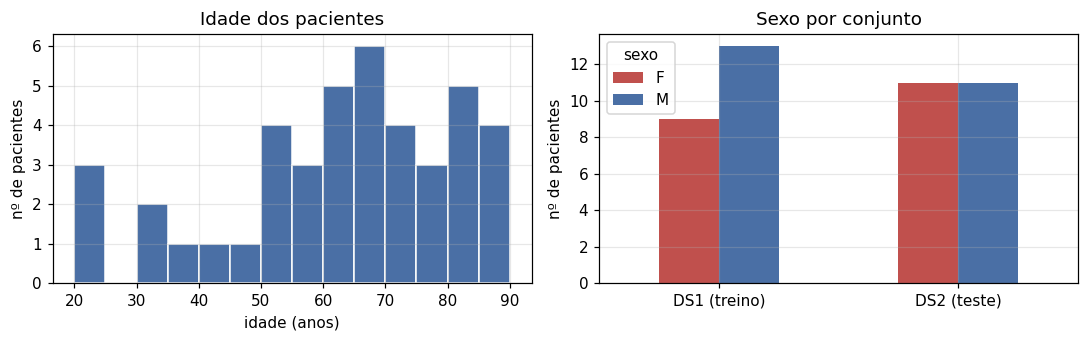

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(usados.idade.dropna(), bins=range(20, 95, 5), color='#4a6fa5', edgecolor='white')
ax[0].set_xlabel('idade (anos)'); ax[0].set_ylabel('nº de pacientes'); ax[0].set_title('Idade dos pacientes')
usados.groupby(['grupo', 'sexo']).size().unstack().plot.bar(ax=ax[1], color=['#c0504d', '#4a6fa5'], rot=0)
ax[1].set_xlabel(''); ax[1].set_title('Sexo por conjunto'); ax[1].set_ylabel('nº de pacientes')
plt.tight_layout(); plt.savefig(PROC_DIR / 'perfil_pacientes.png', bbox_inches='tight'); plt.show()

A base é pequena em número de pessoas (44 pacientes) e concentrada em adultos mais velhos. Ela foi
coletada no Beth Israel Hospital, em Boston, entre 1975 e 1979. Não há informação de etnia nem de
comorbidades. Um modelo treinado aqui pode funcionar pior em populações diferentes (crianças,
outros perfis de paciente, outros equipamentos), e essa limitação entra na discussão ética do artigo.

## 2. O sinal e a filtragem

O filtro passa-faixa Butterworth (0,5-45 Hz, fase zero) remove a deriva da linha de base, que vem da
respiração e do movimento do eletrodo, e o ruído de alta frequência. A derivação usada é a MLII, que
existe em todos os 44 registros. No registro 114 ela está no segundo canal, por isso a função
`ler_registro` procura o canal pelo nome.

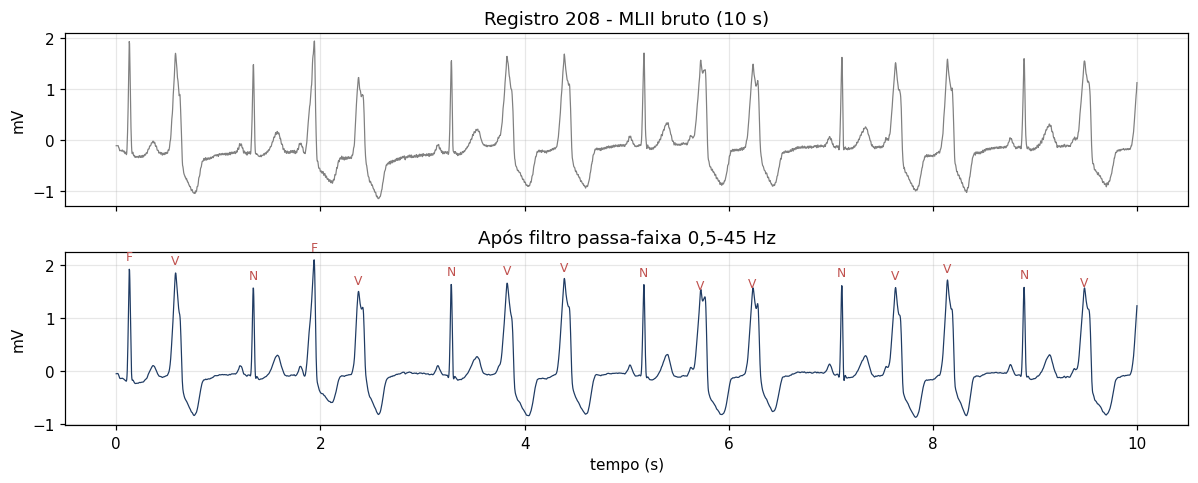

In [5]:
rec, sinal, ann = eu.ler_registro(RAW_DIR, '208')
t = np.arange(10 * eu.FS) / eu.FS
filtrado = eu.filtrar(sinal)
fig, ax = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
ax[0].plot(t, sinal[:len(t)], color='gray', lw=0.8); ax[0].set_title('Registro 208 - MLII bruto (10 s)')
ax[1].plot(t, filtrado[:len(t)], color='#1f3b63', lw=0.8); ax[1].set_title('Após filtro passa-faixa 0,5-45 Hz')
for s, p in zip(ann.symbol, ann.sample):
    if p < len(t) and s in eu.MAPA_AAMI:
        ax[1].annotate(eu.MAPA_AAMI[s], (p / eu.FS, filtrado[p]), xytext=(0, 6),
                       textcoords='offset points', ha='center', fontsize=8, color='#c0504d')
ax[1].set_xlabel('tempo (s)'); ax[0].set_ylabel('mV'); ax[1].set_ylabel('mV')
plt.tight_layout(); plt.savefig(PROC_DIR / 'exemplo_sinal_bruto.png', bbox_inches='tight'); plt.show()

## 3. Distribuição das classes

Os símbolos originais de anotação do MIT-BIH são agrupados nas cinco classes da AAMI EC57: N (normal
e bloqueios de ramo), S (ectópico supraventricular), V (ectópico ventricular), F (fusão) e Q
(desconhecido/estimulado). A divisão de de Chazal et al. (2004) separa os 44 registros em dois
grupos de 22 pacientes, DS1 para treino e DS2 para teste, de modo que nenhum paciente aparece nos
dois. É o protocolo que mede o que interessa na prática: o desempenho em uma pessoa que o modelo
nunca viu.

In [6]:
cont_orig = Counter()
por_registro = []
for r in eu.DS1 + eu.DS2:
    ann = eu.ler_registro(RAW_DIR, r)[2]
    simb = [s for s in ann.symbol if s in eu.MAPA_AAMI]
    cont_orig.update(simb)
    c = Counter(eu.MAPA_AAMI[s] for s in simb)
    por_registro.append({'registro': r, 'conjunto': 'DS1' if r in eu.DS1 else 'DS2',
                         **{k: c.get(k, 0) for k in ['N', 'S', 'V', 'F', 'Q']}})
df_cls = pd.DataFrame(por_registro).set_index('registro')

print('Símbolos originais (44 registros):')
print(pd.Series(cont_orig).sort_values(ascending=False).to_string())

Símbolos originais (44 registros):
N    74546
L     8075
R     7259
V     6903
A     2546
F      803
j      229
a      150
E      106
J       83
e       16
Q       15
S        2


In [7]:
dist = df_cls.groupby('conjunto')[['N', 'S', 'V', 'F', 'Q']].sum().T
dist['total'] = dist.sum(axis=1)
dist['%'] = (100 * dist.total / dist.total.sum()).round(2)
dist.to_csv(PROC_DIR / 'distribuicao_classes.csv')
dist

conjunto,DS1,DS2,total,%
N,45866,44259,90125,89.47
S,944,1837,2781,2.76
V,3788,3221,7009,6.96
F,415,388,803,0.80
Q,8,7,15,0.01


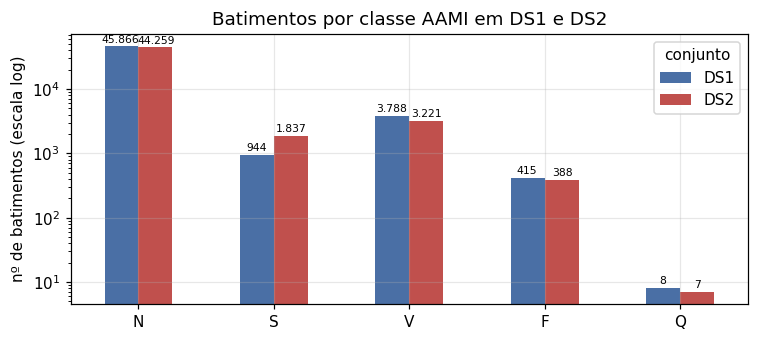

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
d = dist[['DS1', 'DS2']].loc[['N', 'S', 'V', 'F', 'Q']]
d.plot.bar(ax=ax, logy=True, rot=0, color=['#4a6fa5', '#c0504d'])
for i, (a, b) in enumerate(d.values):
    ax.text(i - 0.13, a * 1.15, f'{a:,}'.replace(',', '.'), ha='center', fontsize=7)
    ax.text(i + 0.13, b * 1.15, f'{b:,}'.replace(',', '.'), ha='center', fontsize=7)
ax.set_ylabel('nº de batimentos (escala log)'); ax.set_title('Batimentos por classe AAMI em DS1 e DS2')
plt.tight_layout(); plt.savefig(PROC_DIR / 'distribuicao_classes.png', bbox_inches='tight'); plt.show()

A classe N tem cerca de 90% dos batimentos nos dois conjuntos. A classe Q tem apenas
{{Q}} batimentos depois de excluir os registros com marcapasso, pouco demais para treinar ou
avaliar qualquer coisa, e por isso o modelo trabalha com quatro classes (N, S, V, F), como fazem
de Chazal et al. (2004) e boa parte da literatura que usa esse protocolo.

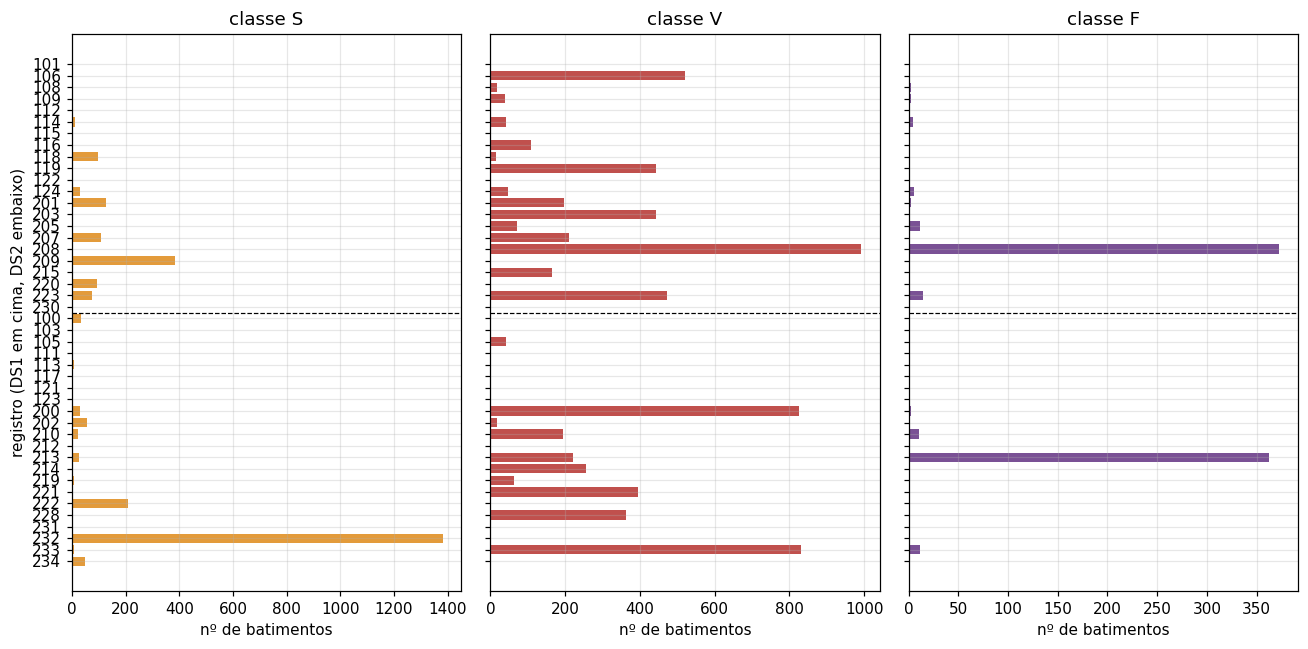

S em DS1: registro 209 concentra 383 de 944 (41%)
S em DS2: registro 232 concentra 1382 de 1837 (75%)
V em DS1: registro 208 concentra 992 de 3788 (26%)
V em DS2: registro 233 concentra 831 de 3221 (26%)
F em DS1: registro 208 concentra 373 de 415 (90%)
F em DS2: registro 213 concentra 362 de 388 (93%)


In [9]:
# Composição por registro: mostra quanto cada paciente contribui para as classes minoritárias
frac = df_cls[['S', 'V', 'F']]
fig, ax = plt.subplots(1, 3, figsize=(12, 6), sharey=True)
for a, c, cor in zip(ax, ['S', 'V', 'F'], ['#e39b3b', '#c0504d', '#7a5195']):
    a.barh(frac.index, frac[c], color=cor)
    a.set_title(f'classe {c}'); a.set_xlabel('nº de batimentos')
ax[0].invert_yaxis(); ax[0].set_ylabel('registro (DS1 em cima, DS2 embaixo)')
for a in ax:
    a.axhline(len(eu.DS1) - 0.5, color='black', lw=0.8, ls='--')
plt.tight_layout(); plt.savefig(PROC_DIR / 'classes_por_registro.png', bbox_inches='tight'); plt.show()

for c in ['S', 'V', 'F']:
    for conj in ['DS1', 'DS2']:
        sub = df_cls[df_cls.conjunto == conj][c]
        print(f'{c} em {conj}: registro {sub.idxmax()} concentra {sub.max()} de {sub.sum()} '
              f'({100 * sub.max() / sub.sum():.0f}%)')

Esse gráfico explica boa parte da dificuldade do problema. No DS2, o registro 232 sozinho tem 75%
dos batimentos S. No DS1, o registro 208 tem quase 90% dos batimentos F, e no DS2 o 213 tem 93%
deles. Na prática, o modelo aprende "fusão" com um único paciente e é testado em outro. Ter poucos
pacientes por classe rara pesa mais que o número de batimentos, e esse ponto volta na análise de
erros do notebook 02.

## 4. Morfologia dos batimentos

Cada batimento é recortado em uma janela de 256 amostras em torno do pico R anotado: 90 amostras
antes (0,25 s, cobre a onda P) e 166 depois (0,46 s, cobre o QRS e a onda T). Na Parte 2 a janela
era de 1 s centrada no pico; em frequências cardíacas altas ela incluía pedaços do batimento
vizinho, por isso foi encurtada. Cada janela é normalizada por z-score.

DS1: (50994, 256)  DS2: (49685, 256)


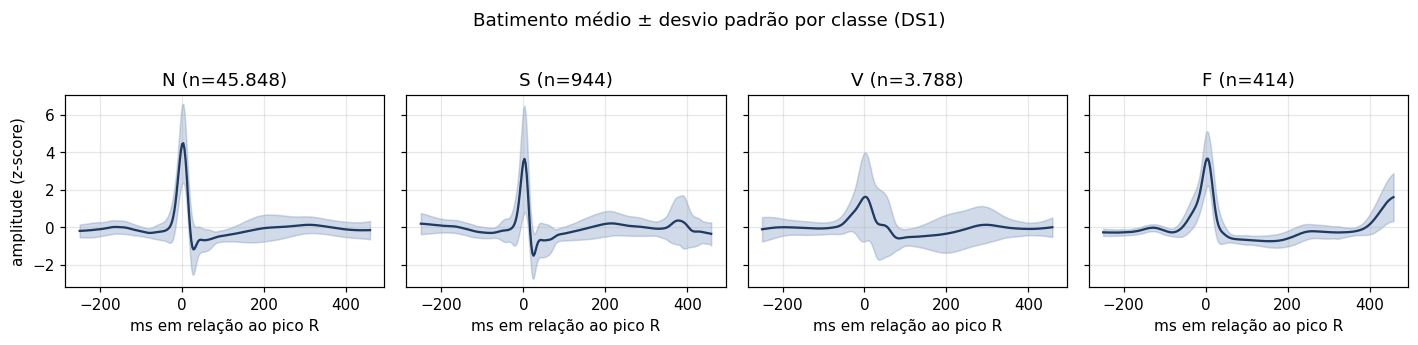

In [10]:
X1, R1, y1, o1 = eu.montar_conjunto(RAW_DIR, eu.DS1)
X2, R2, y2, o2 = eu.montar_conjunto(RAW_DIR, eu.DS2)
print('DS1:', X1.shape, ' DS2:', X2.shape)

t = (np.arange(eu.TAM_JANELA) - eu.JANELA_ANTES) / eu.FS * 1000
fig, ax = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for i, c in enumerate(eu.CLASSES):
    seg = X1[y1 == i]
    m, s = seg.mean(0), seg.std(0)
    ax[i].fill_between(t, m - s, m + s, alpha=0.25, color='#4a6fa5')
    ax[i].plot(t, m, color='#1f3b63')
    ax[i].set_title(f'{c} (n={len(seg):,})'.replace(',', '.')); ax[i].set_xlabel('ms em relação ao pico R')
ax[0].set_ylabel('amplitude (z-score)')
plt.suptitle('Batimento médio ± desvio padrão por classe (DS1)', y=1.03)
plt.tight_layout(); plt.savefig(PROC_DIR / 'exemplo_batimentos_por_classe.png', bbox_inches='tight'); plt.show()

## 5. Atributos de ritmo (intervalos RR)

A forma de onda sozinha não basta para separar um batimento supraventricular de um normal: o
batimento S costuma ter QRS parecido com o normal, só que chega antes da hora. Por isso cada
batimento recebe cinco atributos de ritmo: RR anterior, RR posterior, RR médio local (10 batimentos),
a razão RR anterior/RR local e a razão RR posterior/RR anterior. Os três primeiros são divididos
pela mediana do RR do próprio registro. Sem essa normalização, um RR de 0,6 s seria "precoce" para
um paciente com frequência basal de 60 bpm e normal para outro com 100 bpm.

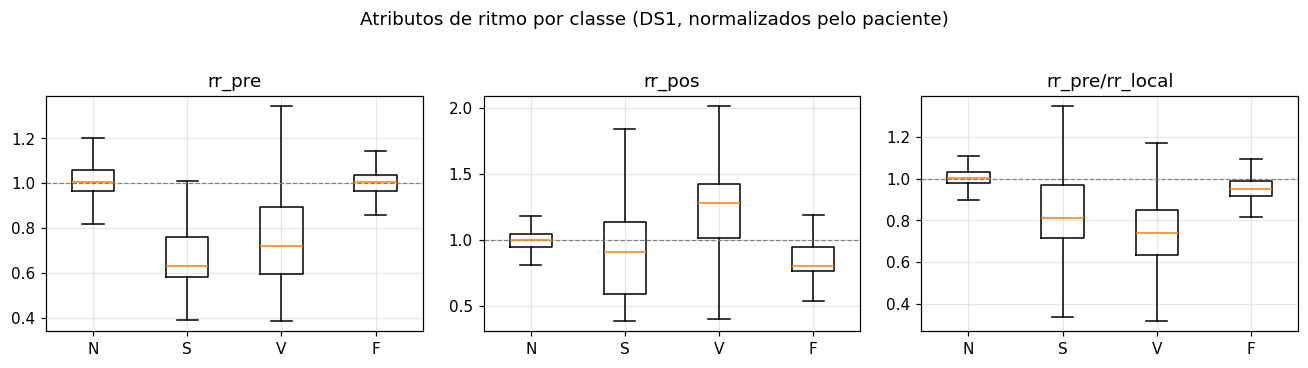

,rr_pre,rr_pos,rr_local,rr_pre/rr_local,rr_pos/rr_pre
classe,,,,,
F,1.00,0.80,1.06,0.95,0.80
N,1.01,1.00,1.01,1.00,0.99
S,0.63,0.91,0.91,0.81,1.21
V,0.72,1.28,0.99,0.74,1.67


In [11]:
df_rr = pd.DataFrame(R1, columns=eu.NOMES_RR)
df_rr['classe'] = [eu.CLASSES[i] for i in y1]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, col in zip(ax, ['rr_pre', 'rr_pos', 'rr_pre/rr_local']):
    dados = [df_rr[df_rr.classe == c][col].clip(0, 3) for c in eu.CLASSES]
    a.boxplot(dados, tick_labels=eu.CLASSES, showfliers=False)
    a.set_title(col); a.axhline(1, color='gray', lw=0.8, ls='--')
plt.suptitle('Atributos de ritmo por classe (DS1, normalizados pelo paciente)', y=1.03)
plt.tight_layout(); plt.savefig(PROC_DIR / 'atributos_rr.png', bbox_inches='tight'); plt.show()
df_rr.groupby('classe')[eu.NOMES_RR].median().round(2)

S e V chegam adiantados (RR anterior mediano de 0,63 e 0,72 do ritmo basal). O V costuma ser
seguido de uma pausa compensatória (RR posterior mediano de 1,28); no S essa pausa quase não
aparece. N e F ficam perto de 1, o que antecipa a dificuldade de separar F pelo ritmo. O atributo separa bem S de N na
maioria dos pacientes, com uma exceção importante que aparece abaixo.

In [12]:
# O caso do registro 232: os batimentos S são a maioria, então a mediana do RR é a do próprio S
for r in ['222', '232']:
    k = o2 == r
    print(f'registro {r}: RR anterior normalizado mediano  N={np.median(R2[k & (y2 == 0), 0]):.2f}  '
          f'S={np.median(R2[k & (y2 == 1), 0]):.2f}   (S={np.sum(k & (y2 == 1))}, N={np.sum(k & (y2 == 0))})')

registro 222: RR anterior normalizado mediano  N=1.03  S=0.62   (S=209, N=2272)
registro 232: RR anterior normalizado mediano  N=2.53  S=0.99   (S=1382, N=398)


No registro 222 o S fica bem abaixo do N, como esperado. No 232 a relação se inverte: os batimentos
S são 78% do registro e definem o ritmo basal, enquanto os N vêm depois de pausas longas. A
normalização por paciente, que ajuda em quase todos os registros, esconde a prematuridade justamente
no paciente que concentra a classe S do conjunto de teste.

## 6. Conjunto processado

O modelo recebe dois canais por batimento: (0) a janela normalizada e (1) a diferença entre ela e o
batimento mediano do mesmo registro. O molde mediano é calculado sem usar rótulos, então pode ser
obtido também para um paciente novo, desde que haja alguns minutos de gravação. A ideia é a mesma do
RR normalizado: o modelo passa a ver o quanto aquele batimento foge do padrão daquela pessoa, o que
ajuda em pacientes cujo batimento normal já é atípico (bloqueio de ramo, por exemplo).

Os arrays ficam em `dataset/processed/mitdb_ds1_ds2.npz` (não versionado no GitHub: cerca de
185 MB e reproduzível por este notebook).

In [13]:
X1c = eu.adicionar_canal_relativo(X1, o1)
X2c = eu.adicionar_canal_relativo(X2, o2)
np.savez_compressed(PROC_DIR / 'mitdb_ds1_ds2.npz', X1=X1c, R1=R1, y1=y1, o1=o1,
                    X2=X2c, R2=R2, y2=y2, o2=o2)

resumo = pd.DataFrame({
    'DS1 (treino)': np.bincount(y1, minlength=4),
    'DS2 (teste)': np.bincount(y2, minlength=4)}, index=eu.CLASSES)
resumo.loc['total'] = resumo.sum()
print('entrada do modelo:', X1c.shape[1:], '(canais, amostras)  +', R1.shape[1], 'atributos RR')
resumo

entrada do modelo: (2, 256) (canais, amostras)  + 5 atributos RR


,DS1 (treino),DS2 (teste)
N,45848,44240
S,944,1837
V,3788,3220
F,414,388
total,50994,49685


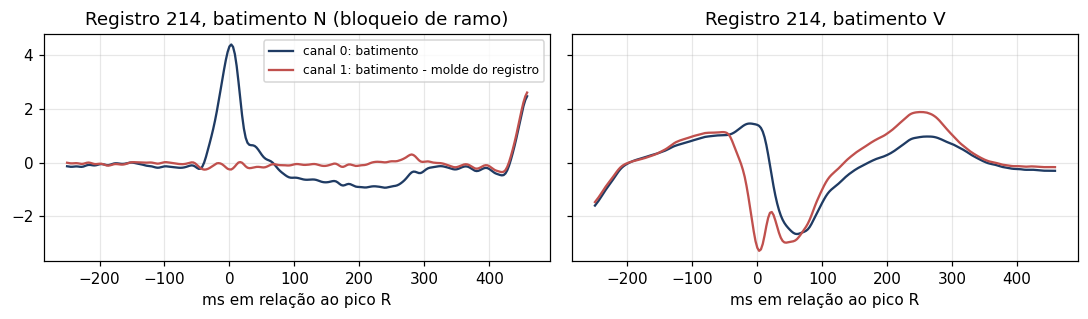

In [14]:
# Exemplo dos dois canais para um batimento N e um V do registro 214 (bloqueio de ramo esquerdo)
k = np.where(o2 == '214')[0]
iN, iV = k[y2[k] == 0][100], k[y2[k] == 2][50]
fig, ax = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for a, i, nome in zip(ax, [iN, iV], ['N (bloqueio de ramo)', 'V']):
    a.plot(t, X2c[i, 0], label='canal 0: batimento', color='#1f3b63')
    a.plot(t, X2c[i, 1], label='canal 1: batimento - molde do registro', color='#c0504d')
    a.set_title(f'Registro 214, batimento {nome}'); a.set_xlabel('ms em relação ao pico R')
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(PROC_DIR / 'canal_relativo.png', bbox_inches='tight'); plt.show()

## 7. O que a análise mostrou

- Os 44 registros sem marcapasso somam 100.679 batimentos nas classes N, S, V e F, com cerca de 90%
  de N. O desbalanceamento exige métricas por classe (sensibilidade, valor preditivo positivo e F1),
  porque a acurácia sozinha premia um modelo que responde "normal" para tudo.
- As classes raras dependem de poucos pacientes (232 para S no teste, 208 e 213 para F). O
  desempenho nessas classes vai refletir em boa parte o quanto esses pacientes se parecem com os do
  treino.
- Os atributos de ritmo separam S e V de N na maioria dos registros, e a normalização por paciente
  falha no 232. Deixamos o registro no teste, por ser o protocolo padrão, e reportamos as métricas
  com e sem ele no notebook 02.